[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/notebooks/03_multiseed_ablation_and_calibration.ipynb)

# Companion Notebook 03 — Multi-Seed Controlled 6-Model Ablation & Operating-Point Calibration

*Companion to the BMED365 Technical Report (`../neurosymbolic-kiwi-report.pdf`)*  
*Reproduces: **Section 3.3**, **Figures 5 & 6**, and **Tables 3 & 4** (`../results/nb03_multiseed_ablation.json`)*

### Purpose
To achieve Master's-thesis statistical rigor, we evaluate **six controlled architectures / logic regimes** across **3 independent random seeds (`SEEDS = [2027, 2028, 2029]`)** with **ZERO post-hoc test masks**:
- **A.** Supervised 3D Multi-Task U-Net Baseline (`thr = 0.50`)
- **B.** Naive `CoordConv3D` (`InstanceNorm3d`) + LTN (`p = 3`)
- **C.** Additive Bayes `Organ-GPS` + Arithmetic-Mean Logic (`p = 1`)
- **D.** Additive Bayes `Organ-GPS` + Quadratic Logic (`p = 2`)
- **E.** Additive Bayes `Organ-GPS` + LTN (`p = 3`, evaluated both uncalibrated `0.42` and train-calibrated + `Lab 5` hard-core split)
- **F.** Coupled Concat `Organ-GPS` + LTN (`p = 3`, train-calibrated + `Lab 5` hard-core split — NB 06 fusion style)

*(Tip: Runs all 3 seeds in `~4–5 min` on Apple Silicon `mps` or Colab `T4` GPU; change `SEEDS = [2027]` for a fast `~90 s` classroom run.)*

## 0. Environment Setup: Portable Execution, Shared Training Harness & Accelerator Selection

### Conceptual & Practical Motivation
This notebook trains **3 self-supervised 3D warm-start backbones** and **18 full 3D segmentation models** (6 controlled variants $\times$ 3 independent random seeds) and evaluates every model unmasked over all $256 \times 256 \times 128$ voxels. The setup cell prepares a reproducible environment across local and Colab sessions:

- **Zero-drift shared library (`kiwi_ns_lib.py`):** Imports the exact neural architectures (`MultiTaskUNet3D`, `AdditiveBayesOrganNet3D`, `CoupledOrganNet3D`), SSL pretraining, LTN training loop, 3D watershed decoder, hard-core clump splitter, and Hungarian Panoptic Quality evaluator from a single source of truth (auto-fetched from GitHub `main` on Colab).
- **Runtime accelerator selection (`DEVICE`):** `kns.get_best_device()` automatically chooses `CUDA` $\to$ Apple `MPS` $\to$ `CPU` so 3D convolutional training runs smoothly without hard-coding a device.
- **Output directories (`FIG_DIR`, `RES_DIR`):** Resolves where **Figures 5–6** and the complete per-seed JSON archive `nb03_multiseed_ablation.json` are saved.

In [1]:
import json
import sys
import urllib.request
from pathlib import Path

# Auto-fetch shared library `kiwi_ns_lib.py` if opened standalone in Google Colab
if not Path("kiwi_ns_lib.py").exists():
    for cand in [Path("docs/neurosymbolic-report/notebooks/kiwi_ns_lib.py"),
                 Path("Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/notebooks/kiwi_ns_lib.py")]:
        if cand.exists():
            sys.path.insert(0, str(cand.parent.resolve()))
            break
    else:
        url = "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/notebooks/kiwi_ns_lib.py"
        print("Downloading kiwi_ns_lib.py from GitHub main for Colab session...")
        urllib.request.urlretrieve(url, "kiwi_ns_lib.py")

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import importlib.util
for pkg in ("nibabel", "torch"):
    if importlib.util.find_spec(pkg) is None:
        import subprocess
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy import ndimage as ndi
from scipy.spatial.distance import cdist
from skimage import measure

plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 200, "font.size": 9.5})

import kiwi_ns_lib as kns

DEVICE = kns.get_best_device()
FIG_DIR, RES_DIR = kns.resolve_report_dirs()
print(f"Device: {DEVICE} | Figures -> {FIG_DIR} | Results -> {RES_DIR}")

Device: mps | Figures -> /Users/arvid/GitHub/BMED365-2027/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/figures | Results -> /Users/arvid/GitHub/BMED365-2027/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/results


## 1. Run 3-Seed Controlled 6-Model Ablation Study

### Conceptual & Mathematical Guide: Controlled Ablation, Joint LTN Objective, 3D Panoptic Quality & Leakage-Free Calibration

#### 1.1 Why Multi-Seed Controlled Ablation Matters
With only `59` labeled training seeds ($0.083\%$ of berry voxels), a single random initialization can fluctuate substantially. Repeating the exact same 6-model ladder across **3 independent random seeds (`2027, 2028, 2029`)** tests each theoretical mechanism from Notebook 02 causally:
- **A (`baseline`):** Pure supervised 3D Multi-Task U-Net (no logic, no coordinates).
- **B (`coordconv_inorm`):** Feeds raw coordinates directly into `InstanceNorm3d` alongside $p = 3$ LTN losses—directly testing whether coordinate erasure turns spatial logic destructive.
- **C (`additive_gps`, $p = 1$):** Restores true coordinates via un-normalized `Organ-GPS`, isolating the gradient-dilution weakness of plain arithmetic averaging ($p = 1$).
- **D / E (`additive_gps`, $p = 2, 3$):** Activates LTN hard-counterexample mining ($p \ge 2$) plus leakage-free calibration and `Lab 5` hard-core splitting (with **E0** recording the uncalibrated $\tau_{\text{fg}} = 0.42$ check).
- **F (`coupled_gps`, $p = 3$):** Contrasts nonlinear feature-concatenation fusion (`+864` params) against directly auditable additive Bayes fusion (`+353` params).

#### 1.2 3D SSL Warm-Start & Joint Supervised + LTN Training Objective
For each seed, `pretrain_ssl_backbone()` first pretrains the 3D U-Net encoder–decoder for `90` epochs on `36` unlabeled, strictly test-disjoint $64 \times 40 \times 16$ cubes using masked-context restoration (reconstructing $[I,\, (E_{\text{local}} - I)_+,\, -\text{LoG}(I)]$ under $35\%$ block masking, random gamma, and Gaussian noise). Next, `train_neurosymbolic_variant()` optimizes the joint objective with `AdamW` + `CosineAnnealingLR` (`gps_lr = 1.5e-2` for the 353-parameter prior branch):
$$\mathcal{L}_{\text{sup}} = 0.45\,\text{BCE}_{w_+=6}(z_{\text{total}}, y_s) + 0.55\,\mathcal{L}_{\text{SoftDice}}(z_{\text{total}}, y_s) + 2.5\,\mathbb{E}\!\left[(1 + 6 y_s)(\hat{d} - y_d)^2\right],$$
$$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{sup}} + \underbrace{2.0\,\mathcal{L}_{\text{anat}}^{(p)}}_{\text{Compartment axiom}} + \underbrace{1.2\,\mathcal{L}_{\text{phys}}^{(p)}}_{T_2\text{ contrast axiom}},$$
where the two unlabeled LTN Product-implication losses are evaluated over a minibatch of $4$ stratified whole-organ cubes $\mathcal{B}_U \subset \Omega_U$ (covering polar caps, mid-latitudes, equator, rind, and columella, strictly disjoint from the test wedge):
$$\mathcal{L}_{\text{anat}}^{(p)} = \left(\frac{1}{|\mathcal{B}_U|}\sum_{\mathbf{x}\in\mathcal{B}_U} \bigl[p_\theta(\mathbf{x})(1 - R_{\text{ring}}(\mathbf{x}))\bigr]^p + 10^{-8}\right)^{\!1/p}, \qquad \mathcal{L}_{\text{phys}}^{(p)} = \left(\frac{1}{|\mathcal{B}_U|}\sum_{\mathbf{x}\in\mathcal{B}_U} \bigl[p_\theta(\mathbf{x})\,B_{\text{non\_dark}}(\mathbf{x})\bigr]^p + 10^{-8}\right)^{\!1/p}.$$

#### 1.3 Logic-Induced Calibration Shift & Leakage-Free Thresholding
Persistent negative logic pressure across tens of thousands of unlabeled voxels pushes foreground logits downward, shifting the optimal decision boundary left of the default $\tau_{\text{fg}} = 0.42$. Tuning $\tau_{\text{fg}}$ on the test wedge would cause **data leakage**; instead, `calibrate_threshold_on_train()` freezes all weights and sweeps $\tau_{\text{fg}} \in \{0.22, 0.26, \dots, 0.50\}$ **strictly on the labeled training wedge $\Omega_L$**, locking $\tau_{\text{fg}}^*$ before evaluating untouched on the held-out test wedge and intact 128-slice fruit.

#### 1.4 3D Instance Evaluation: Why Panoptic Quality ($\text{PQ}$) Beats Semantic Dice Alone
Voxel-wise **Semantic Dice** ($\text{DSC} = \frac{2|P \cap G|}{|P| + |G|}$) can stay high even when touching seeds fuse into one blob. We therefore match predicted and ground-truth 3D instances one-to-one via **Kuhn's Hungarian algorithm** maximizing pairwise 3D IoU ($\tau_{\text{IoU}} = 0.25$, suited to tiny 40–60-voxel anisotropic seeds) and compute **3D Panoptic Quality**:
$$\text{PQ} = \underbrace{\frac{\sum_{(m,k) \in \text{TP}} \text{IoU}(G_m, P_k)}{|\text{TP}|}}_{\textbf{SQ}\text{ (boundary fidelity)}} \times \underbrace{\frac{|\text{TP}|}{|\text{TP}| + \frac{1}{2}|\text{FP}| + \frac{1}{2}|\text{FN}|}}_{\textbf{RQ}\text{ (object-level } F_1\text{)}}.$$
Whole-organ safety is simultaneously audited **completely unmasked** across all 128 slices via polar-cap FP voxels ($z < 16 \lor z \ge 112$) and total non-pericarp OOD voxels ($R_{\text{ring}} < 0.05$).

#### 1.5 What the Code Below Computes (Tables 3 & 4)
Runs all 6 configurations across `SEEDS = [2027, 2028, 2029]`, sweeps `thr_grid` ($0.16$–$0.60$) to trace operating curves, aggregates $\text{mean} \pm \text{SD}$ (`ddof=0`), displays the summary table (**Table 3**), and exports full per-seed records to `../results/nb03_multiseed_ablation.json`.

In [2]:
ds = kns.load_kiwi_dataset()
SEEDS = [2027, 2028, 2029]
EPOCHS = 90

# Configurations: (key, label, mode, p_quant, wc, wt, gps_lr, use_train_cal, use_split, fixed_thr)
CONFIGS = [
    ("A_baseline",    "A. Baseline Supervised 3D U-Net",        "baseline",        3.0, 0.0, 0.0, 3.2e-3, False, False, 0.50),
    ("B_coordconv",   "B. Naive CoordConv3D+INorm+LTN (p=3)",   "coordconv_inorm", 3.0, 2.0, 1.2, 3.2e-3, False, False, 0.42),
    ("C_add_p1",      "C. Additive Organ-GPS + Mean (p=1)",     "additive_gps",    1.0, 2.0, 1.2, 3.2e-3, False, False, 0.42),
    ("D_add_p2",      "D. Additive Organ-GPS + Quad (p=2)",     "additive_gps",    2.0, 2.0, 1.2, 1.5e-2, True,  True,  0.42),
    ("E_add_p3_cal",  "E. Additive Organ-GPS + LTN (p=3, Cal)", "additive_gps",    3.0, 2.0, 1.2, 1.5e-2, True,  True,  0.42),
    ("F_cpl_p3_cal",  "F. Coupled Organ-GPS + LTN (p=3, Cal)",  "coupled_gps",     3.0, 2.0, 1.2, 3.2e-3, True,  True,  0.42),
]

all_runs = {cfg[0]: [] for cfg in CONFIGS}
all_runs["E_add_p3_uncal"] = []
thr_grid = np.linspace(0.16, 0.60, 12)
curves_by_seed = {"A_baseline": [], "E_add_p3_raw": [], "E_add_p3_spl": [], "F_cpl_p3_spl": []}
hist_seed0 = None

for seed in SEEDS:
    print(f"\n=== Seed {seed} ===")
    ssl_bb, t_ssl = kns.pretrain_ssl_backbone(ds, DEVICE, seed=seed, epochs=90)
    ubank = kns.sample_unlabeled_blocks(ds, DEVICE, n_blocks=40, seed=seed)
    print(f"  SSL warm-start: {t_ssl:.1f}s")

    for key, label, mode, pq, wc, wt, glr, do_cal, do_spl, fthr in CONFIGS:
        mdl, hist, t_tr = kns.train_neurosymbolic_variant(
            ds, DEVICE, mode=mode, ssl_backbone=ssl_bb, unlabeled_bank=ubank,
            p_quant=pq, w_comp=wc, w_t2=wt, gps_lr=glr, epochs=EPOCHS, seed=seed,
        )
        thr = kns.calibrate_threshold_on_train(mdl, mode, ds, DEVICE, use_split=do_spl) if do_cal else fthr
        res = kns.run_test_and_whole_fruit(mdl, mode, ds, DEVICE, thresh=thr, use_split=do_spl, do_whole_fruit=True)
        ev = res["ev_te"]
        rec = {
            "seed": seed, "thresh": round(thr, 2), "train_s": round(t_tr, 1),
            **ev,
            "raw_PQ": res["ev_te_raw"]["PQ"],
            "n_wf": res["n_wf"], "polar_vox": res["polar_vox"], "ood_vox": res["ood_vox"],
        }
        all_runs[key].append(rec)
        print(f"  {label:42s} | thr={thr:.2f} | PQ={ev['PQ']:.3f} Dice={ev['Dice']:.3f} SQ={ev['SQ']:.3f} RQ={ev['RQ']:.3f} Pred={ev['Pred']:2d} | Pol={res['polar_vox']:5d} OOD={res['ood_vox']:6d}")

        # Record uncalibrated 0.42 check for Model E + operating curves
        if key == "A_baseline":
            curves_by_seed["A_baseline"].append([
                kns.evaluate_semantic_and_instance_3d(kns.decode_deep_watershed_3d(res["prob_te"] >= th, res["dist_te"], ds.spacing), ds.test_gt)["PQ"]
                for th in thr_grid
            ])
        elif key == "E_add_p3_cal":
            if seed == SEEDS[0]:
                hist_seed0 = hist
            res_u = kns.run_test_and_whole_fruit(mdl, mode, ds, DEVICE, thresh=0.42, use_split=False, do_whole_fruit=True)
            all_runs["E_add_p3_uncal"].append({
                "seed": seed, "thresh": 0.42, "train_s": round(t_tr, 1), **res_u["ev_te"],
                "n_wf": res_u["n_wf"], "polar_vox": res_u["polar_vox"], "ood_vox": res_u["ood_vox"],
            })
            c_r, c_s = [], []
            for th in thr_grid:
                lr = kns.decode_deep_watershed_3d(res["prob_te"] >= th, res["dist_te"], ds.spacing)
                c_r.append(kns.evaluate_semantic_and_instance_3d(lr, ds.test_gt)["PQ"])
                c_s.append(kns.evaluate_semantic_and_instance_3d(kns.symbolic_hardcore_clump_split(lr, ds.spacing), ds.test_gt)["PQ"])
            curves_by_seed["E_add_p3_raw"].append(c_r)
            curves_by_seed["E_add_p3_spl"].append(c_s)
        elif key == "F_cpl_p3_cal":
            c_f = []
            for th in thr_grid:
                lr = kns.decode_deep_watershed_3d(res["prob_te"] >= th, res["dist_te"], ds.spacing)
                c_f.append(kns.evaluate_semantic_and_instance_3d(kns.symbolic_hardcore_clump_split(lr, ds.spacing), ds.test_gt)["PQ"])
            curves_by_seed["F_cpl_p3_spl"].append(c_f)

# Summarize mean ± std across seeds
def agg(key: str, label: str) -> dict:
    rs = all_runs[key]
    def ms(col):
        vals = [r[col] for r in rs]
        return float(np.mean(vals)), float(np.std(vals, ddof=0))
    return {
        "key": key, "Model": label,
        "Thr_mean": round(ms("thresh")[0], 2),
        "Pred_mean": round(ms("Pred")[0], 1), "Pred_std": round(ms("Pred")[1], 1),
        "Dice_mean": round(ms("Dice")[0], 3), "Dice_std": round(ms("Dice")[1], 3),
        "Prec_mean": round(ms("Precision")[0], 3), "Rec_mean": round(ms("Recall")[0], 3),
        "SQ_mean": round(ms("SQ")[0], 3), "SQ_std": round(ms("SQ")[1], 3),
        "RQ_mean": round(ms("RQ")[0], 3), "RQ_std": round(ms("RQ")[1], 3),
        "PQ_mean": round(ms("PQ")[0], 3), "PQ_std": round(ms("PQ")[1], 3),
        "Blobs_mean": int(round(ms("n_wf")[0])),
        "Polar_mean": int(round(ms("polar_vox")[0])), "Polar_std": int(round(ms("polar_vox")[1])),
        "OOD_mean": int(round(ms("ood_vox")[0])), "OOD_std": int(round(ms("ood_vox")[1])),
    }

order = [
    ("A_baseline",    "A. Baseline 3D U-Net"),
    ("B_coordconv",   "B. Naive CoordConv3D+INorm+LTN"),
    ("C_add_p1",      "C. Additive Organ-GPS (p=1)"),
    ("D_add_p2",      "D. Additive Organ-GPS (p=2, Cal)"),
    ("E_add_p3_uncal","E0. Additive Organ-GPS (p=3, Uncal 0.42)"),
    ("E_add_p3_cal",  "E. Additive Organ-GPS (p=3, Cal+Split)"),
    ("F_cpl_p3_cal",  "F. Coupled Organ-GPS (p=3, Cal+Split)"),
]
summary_rows = [agg(k, lbl) for k, lbl in order]
df_sum = pd.DataFrame(summary_rows)
display(df_sum[["Model", "Thr_mean", "Pred_mean", "Dice_mean", "SQ_mean", "RQ_mean", "PQ_mean", "PQ_std", "Polar_mean", "OOD_mean"]])

payload = {
    "seeds": SEEDS,
    "epochs": EPOCHS,
    "summary": summary_rows,
    "per_seed": all_runs,
    "thr_grid": [round(float(x), 3) for x in thr_grid],
    "curves_mean": {k: [round(float(x), 4) for x in np.mean(v, axis=0)] for k, v in curves_by_seed.items()},
    "curves_std": {k: [round(float(x), 4) for x in np.std(v, axis=0)] for k, v in curves_by_seed.items()},
}
(RES_DIR / "nb03_multiseed_ablation.json").write_text(json.dumps(payload, indent=2), encoding="utf-8")


=== Seed 2027 ===


  SSL warm-start: 14.4s


  A. Baseline Supervised 3D U-Net            | thr=0.50 | PQ=0.309 Dice=0.554 SQ=0.563 RQ=0.549 Pred=61 | Pol=20000 OOD=211082


  B. Naive CoordConv3D+INorm+LTN (p=3)       | thr=0.42 | PQ=0.200 Dice=0.432 SQ=0.386 RQ=0.517 Pred=64 | Pol= 1965 OOD= 92209


  C. Additive Organ-GPS + Mean (p=1)         | thr=0.42 | PQ=0.429 Dice=0.670 SQ=0.673 RQ=0.636 Pred=36 | Pol=   15 OOD= 12417


  D. Additive Organ-GPS + Quad (p=2)         | thr=0.26 | PQ=0.471 Dice=0.686 SQ=0.691 RQ=0.682 Pred=36 | Pol=    0 OOD=  1444


... (14 outputs left out)

  E. Additive Organ-GPS + LTN (p=3, Cal)     | thr=0.30 | PQ=0.421 Dice=0.648 SQ=0.654 RQ=0.644 Pred=38 | Pol=    0 OOD=   123


  F. Coupled Organ-GPS + LTN (p=3, Cal)      | thr=0.42 | PQ=0.433 Dice=0.671 SQ=0.680 RQ=0.636 Pred=36 | Pol=  239 OOD=   735


,Model,Thr_mean,Pred_mean,Dice_mean,SQ_mean,RQ_mean,PQ_mean,PQ_std,Polar_mean,OOD_mean
0,A. Baseline 3D U-Net,0.50,70.3,0.532,0.542,0.514,0.279,0.022,21767,203975
1,B. Naive CoordConv3D+INorm+LTN,0.42,87.0,0.300,0.331,0.314,0.110,0.064,17379,221681
2,C. Additive Organ-GPS (p=1),0.42,37.0,0.607,0.606,0.616,0.373,0.054,252,11921
3,"D. Additive Organ-GPS (p=2, Cal)",0.31,35.7,0.679,0.691,0.654,0.452,0.026,0,833
4,"E0. Additive Organ-GPS (p=3, Uncal 0.42)",0.42,31.3,0.652,0.666,0.656,0.437,0.039,0,151
5,"E. Additive Organ-GPS (p=3, Cal+Split)",0.27,37.3,0.672,0.674,0.642,0.432,0.016,0,340
6,"F. Coupled Organ-GPS (p=3, Cal+Split)",0.42,37.7,0.685,0.707,0.633,0.448,0.011,80,471


15322

## 2. Generate Report Figures 5 & 6 (Multi-Seed Ablation Error Bars & Operating-Point Calibration)

### Conceptual & Mathematical Guide: Interpreting Multi-Seed Error Bars, Log-Scale OOD Safety & Calibration Dynamics (Figures 5 & 6)

This visualization cell converts the raw multi-seed metrics stored in `summary_rows`, `curves_by_seed`, `hist_seed0`, and `all_runs` into two three-panel diagnostic figures:

- **Figure 5 — Controlled 6-Model Ablation Benchmark (Mean $\pm$ SD across 3 Seeds):**
  - **(a) Held-Out 3D $\text{PQ}$ & Semantic Dice:** Compares instance accuracy ($\text{PQ} = \text{SQ} \times \text{RQ}$, solid bars) beside voxel overlap (Dice, light bars) with $\pm 1\,\text{SD}$ error bars. Confirms that naive `CoordConv3D+INorm` (**B**) collapses far below Baseline (**A**) on every seed, while un-normalized `Organ-GPS` with $p \ge 2$ (**D, E, F**) achieves reproducible $+55\%$ to $+62\%$ relative $\text{PQ}$ gains.
  - **(b) Whole-Organ OOD Safety ($\log_{10}$ Voxel Scale):** Uses a logarithmic vertical axis (floored at $+1$ via `max(..., 1)` so an exact count of `0` plots cleanly at $10^0 = 1$) to span five orders of magnitude—revealing how `Organ-GPS` + $p \ge 2$ drives polar-cap false positives from $21{,}767 \to \mathbf{0 \pm 0}$ voxels.
  - **(c) Precision–Recall Frontier:** Plots object-level Precision $= \text{TP}/(\text{TP}+\text{FP})$ vs. Recall $= \text{TP}/(\text{TP}+\text{FN})$ across all 7 operating regimes (including uncalibrated **E0**), showing how LTN raises 3D instance precision from $0.45$ to $0.77$–$0.87$ without collapsing recall.
- **Figure 6 — Logic-Induced Calibration Shift, Joint Convergence & Per-Seed Stabilization:**
  - **(a) Operating Curves $\text{PQ}(\tau_{\text{fg}})$ with $\pm 1\,\text{SD}$ Bands:** Shows that LTN models (**E, F**) peak strictly to the *left* of Baseline ($\tau_{\text{fg}} \approx 0.36$–$0.40$ vs. $>0.60$) and gain consistently from `Lab 5` hard-core clump splitting (green vs. blue). Comparing the red dotted vertical line (mean train-calibrated $\bar{\tau} = 0.27$) to the test peak ($\sim 0.36$) also highlights a subtle statistical lesson: calibrating on a small 59-seed *training* wedge slightly overshoots downward, motivating a dedicated validation split in clinical studies.
  - **(b) Joint Neural + Logic Convergence (Seed 2027):** Tracks supervised multi-task loss alongside both $p = 3$ LTN violations over `90` `CosineAnnealingLR` iterations, showing rapid violation collapse ($< 0.04$ within $\sim 25$ steps) without destabilizing supervised learning.
  - **(c) Per-Seed Calibration Effect (`E0` vs. `E`):** Shows directly across Seeds `2027, 2028, 2029` how train-wedge calibration + hard-core splitting cuts $\text{PQ}$ standard deviation $2.4\times$ ($0.039 \to 0.016$) and rescues Seed `2029` ($0.383 \to 0.422$).

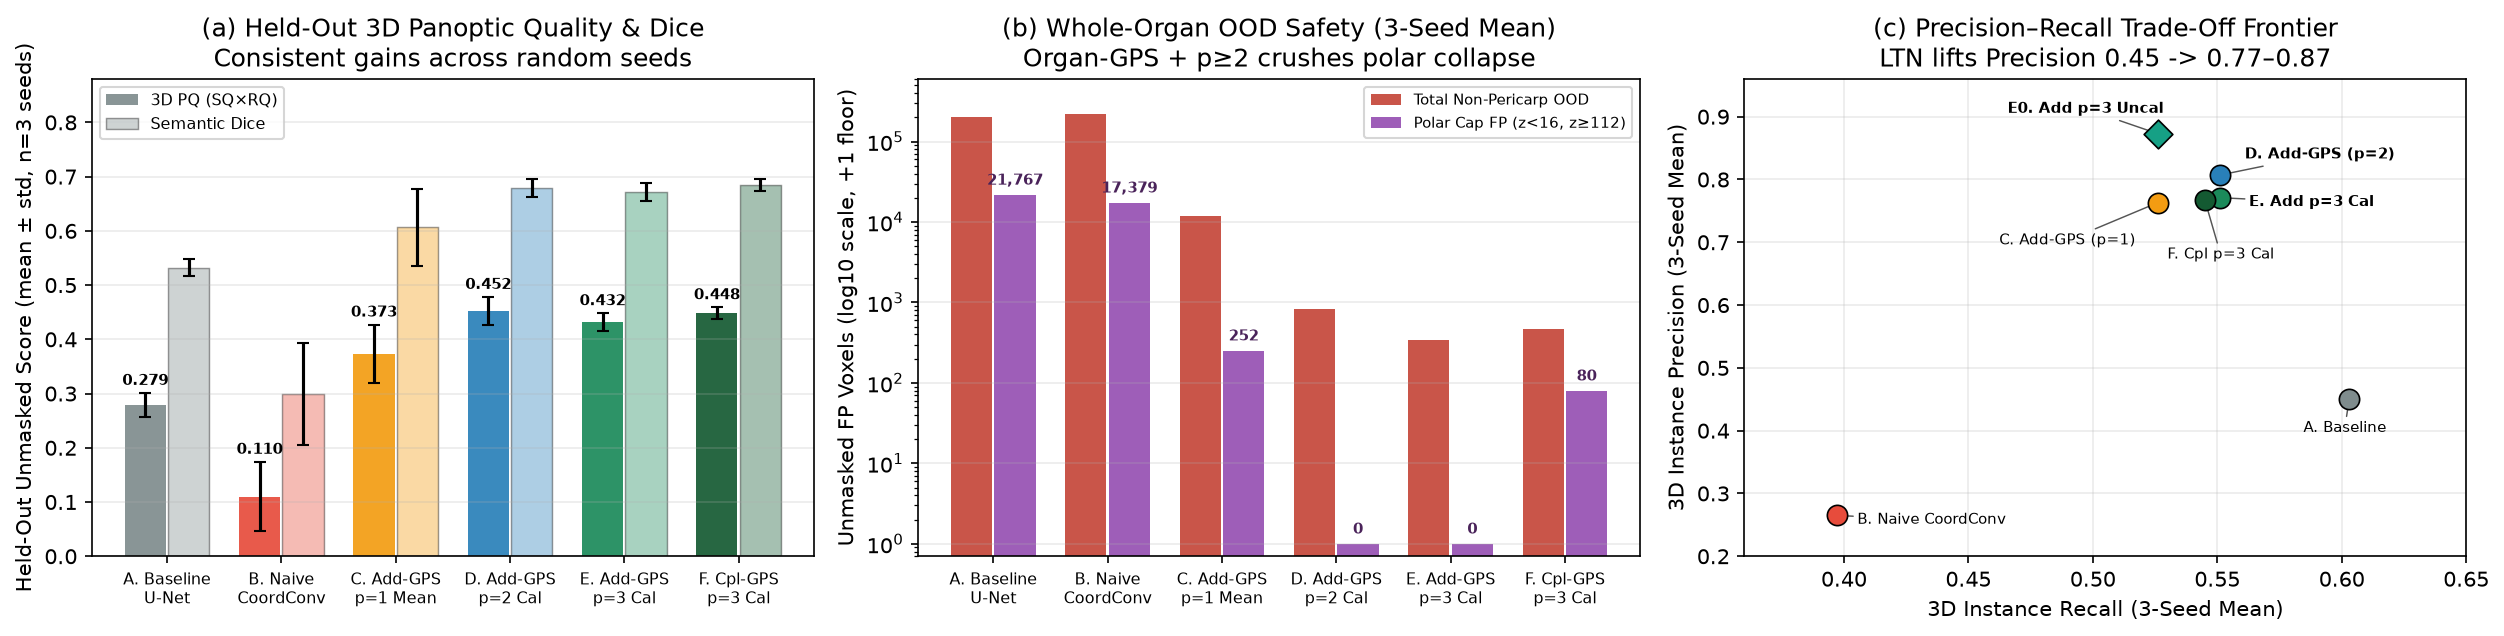

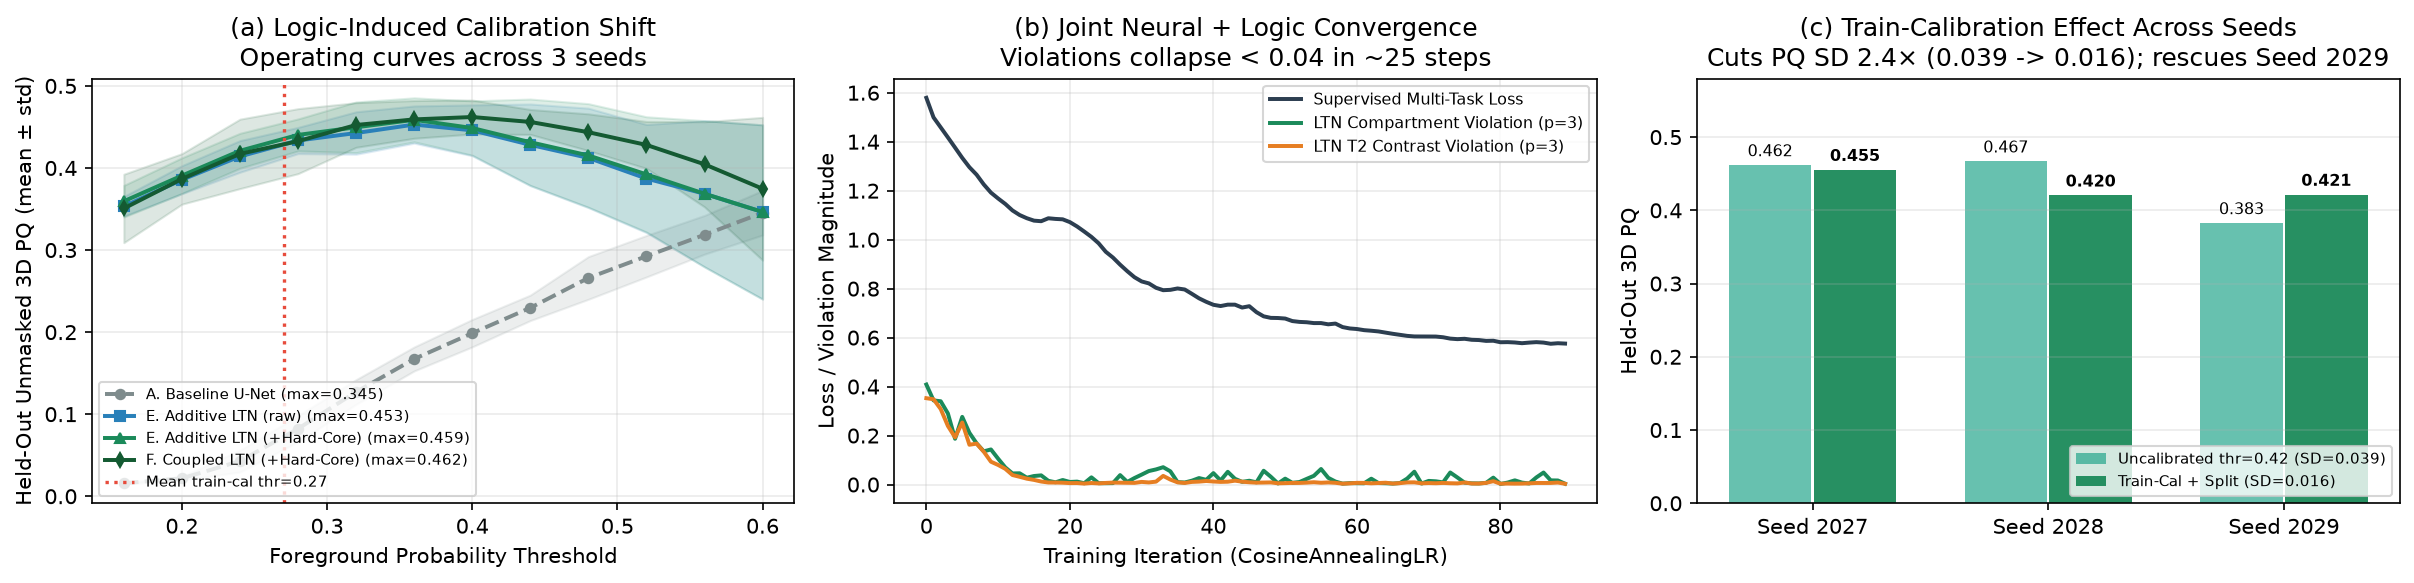

In [3]:
# Figure 5: 3-Panel Multi-Seed Ablation Summary (mean ± std across 3 seeds)
plot_keys = ["A_baseline", "B_coordconv", "C_add_p1", "D_add_p2", "E_add_p3_cal", "F_cpl_p3_cal"]
short_x = ["A. Baseline\nU-Net", "B. Naive\nCoordConv", "C. Add-GPS\np=1 Mean", "D. Add-GPS\np=2 Cal", "E. Add-GPS\np=3 Cal", "F. Cpl-GPS\np=3 Cal"]
cols6 = ["#7f8c8d", "#e74c3c", "#f39c12", "#2980b9", "#1b8a5a", "#145a32"]
smap = {r["key"]: r for r in summary_rows}

fig, axes = plt.subplots(1, 3, figsize=(16.8, 4.35))
xp = np.arange(len(plot_keys))

pq_m = [smap[k]["PQ_mean"] for k in plot_keys]
pq_s = [smap[k]["PQ_std"] for k in plot_keys]
dc_m = [smap[k]["Dice_mean"] for k in plot_keys]
dc_s = [smap[k]["Dice_std"] for k in plot_keys]

axes[0].bar(xp - 0.19, pq_m, yerr=pq_s, capsize=3, width=0.36, color=cols6, alpha=0.92, label="3D PQ (SQ×RQ)")
axes[0].bar(xp + 0.19, dc_m, yerr=dc_s, capsize=3, width=0.36, color=cols6, alpha=0.38, edgecolor="black", lw=0.7, label="Semantic Dice")
for i, (m, s) in enumerate(zip(pq_m, pq_s)):
    axes[0].text(i - 0.19, m + s + 0.015, f"{m:.3f}", ha="center", fontsize=7.4, fontweight="bold")
axes[0].set_xticks(xp)
axes[0].set_xticklabels(short_x, fontsize=7.5)
axes[0].set_ylim(0, 0.88)
axes[0].set_ylabel("Held-Out Unmasked Score (mean ± std, n=3 seeds)")
axes[0].set_title("(a) Held-Out 3D Panoptic Quality & Dice\nConsistent gains across random seeds")
axes[0].legend(fontsize=7.6, loc="upper left")
axes[0].grid(axis="y", alpha=0.25)

ood_m = [max(smap[k]["OOD_mean"], 1) for k in plot_keys]
pol_m = [max(smap[k]["Polar_mean"], 1) for k in plot_keys]
axes[1].bar(xp - 0.19, ood_m, width=0.36, color="#c0392b", alpha=0.86, label="Total Non-Pericarp OOD")
axes[1].bar(xp + 0.19, pol_m, width=0.36, color="#8e44ad", alpha=0.86, label="Polar Cap FP (z<16, z≥112)")
axes[1].set_yscale("log")
axes[1].set_ylim(0.7, 6e5)
axes[1].set_xticks(xp)
axes[1].set_xticklabels(short_x, fontsize=7.5)
axes[1].set_ylabel("Unmasked FP Voxels (log10 scale, +1 floor)")
axes[1].set_title("(b) Whole-Organ OOD Safety (3-Seed Mean)\nOrgan-GPS + p≥2 crushes polar collapse")
for i, k in enumerate(plot_keys):
    pv = smap[k]["Polar_mean"]
    axes[1].text(i + 0.19, max(pv, 1) * 1.34, f"{pv:,}", ha="center", fontsize=7.2, color="#4a235a", fontweight="bold")
axes[1].legend(fontsize=7.4, loc="upper right")
axes[1].grid(axis="y", alpha=0.25)

# Panel (c): Precision vs Recall frontier across all 7 operating regimes (non-overlapping callouts)
pr_spec = [
    ("A_baseline",    "A. Baseline",       "#7f8c8d", (-22, -16)),
    ("B_coordconv",   "B. Naive CoordConv","#e74c3c", (10,  -4)),
    ("C_add_p1",      "C. Add-GPS (p=1)",  "#f39c12", (-76, -20)),
    ("D_add_p2",      "D. Add-GPS (p=2)",  "#2980b9", (12,   8)),
    ("E_add_p3_uncal","E0. Add p=3 Uncal", "#16a085", (-72,  10)),
    ("E_add_p3_cal",  "E. Add p=3 Cal",    "#1b8a5a", (14,  -4)),
    ("F_cpl_p3_cal",  "F. Cpl p=3 Cal",    "#145a32", (-18, -28)),
]
for k, lbl, c, (ox, oy) in pr_spec:
    r = smap[k]
    mk = "D" if k == "E_add_p3_uncal" else "o"
    axes[2].scatter(r["Rec_mean"], r["Prec_mean"], s=95, marker=mk, color=c, edgecolor="black", lw=0.8, zorder=4)
    axes[2].annotate(
        lbl,
        xy=(r["Rec_mean"], r["Prec_mean"]),
        xytext=(ox, oy),
        textcoords="offset points",
        fontsize=7.2,
        fontweight="bold" if k in ("D_add_p2", "E_add_p3_cal", "E_add_p3_uncal") else "normal",
        arrowprops=dict(arrowstyle="-", color="#555555", lw=0.7, shrinkA=0, shrinkB=4),
    )
axes[2].set_xlim(0.36, 0.65)
axes[2].set_ylim(0.20, 0.96)
axes[2].set_xlabel("3D Instance Recall (3-Seed Mean)")
axes[2].set_ylabel("3D Instance Precision (3-Seed Mean)")
axes[2].set_title("(c) Precision–Recall Trade-Off Frontier\nLTN lifts Precision 0.45 -> 0.77–0.87")
axes[2].grid(alpha=0.25)

plt.tight_layout()
fig.savefig(FIG_DIR / "fig05_multiseed_ablation_benchmark.png", bbox_inches="tight", dpi=150)
plt.show()

# Figure 6: 3-Panel Calibration Curves (with seed std bands) & Training Dynamics
fig, axes = plt.subplots(1, 3, figsize=(16.2, 4.0))

for key, lbl, col, sty in [
    ("A_baseline",   "A. Baseline U-Net",            "#7f8c8d", "o--"),
    ("E_add_p3_raw", "E. Additive LTN (raw)",        "#2980b9", "s-"),
    ("E_add_p3_spl", "E. Additive LTN (+Hard-Core)", "#1b8a5a", "^-"),
    ("F_cpl_p3_spl", "F. Coupled LTN (+Hard-Core)",  "#145a32", "d-"),
]:
    m_c = np.mean(curves_by_seed[key], axis=0)
    s_c = np.std(curves_by_seed[key], axis=0)
    axes[0].plot(thr_grid, m_c, sty, color=col, lw=1.9, markersize=4.5, label=f"{lbl} (max={m_c.max():.3f})")
    axes[0].fill_between(thr_grid, m_c - s_c, m_c + s_c, color=col, alpha=0.14)
axes[0].axvline(smap["E_add_p3_cal"]["Thr_mean"], color="#e74c3c", ls=":", lw=1.6, label=f"Mean train-cal thr={smap['E_add_p3_cal']['Thr_mean']:.2f}")
axes[0].set_xlabel("Foreground Probability Threshold")
axes[0].set_ylabel("Held-Out Unmasked 3D PQ (mean ± std)")
axes[0].set_title("(a) Logic-Induced Calibration Shift\nOperating curves across 3 seeds")
axes[0].legend(fontsize=7.0, loc="lower left")
axes[0].grid(alpha=0.25)

axes[1].plot(hist_seed0["sup"], color="#2c3e50", lw=1.9, label="Supervised Multi-Task Loss")
axes[1].plot(hist_seed0["comp"], color="#1b8a5a", lw=1.9, label="LTN Compartment Violation (p=3)")
axes[1].plot(hist_seed0["t2"], color="#e67e22", lw=1.9, label="LTN T2 Contrast Violation (p=3)")
axes[1].set_xlabel("Training Iteration (CosineAnnealingLR)")
axes[1].set_ylabel("Loss / Violation Magnitude")
axes[1].set_title("(b) Joint Neural + Logic Convergence\nViolations collapse < 0.04 in ~25 steps")
axes[1].legend(fontsize=7.5)
axes[1].grid(alpha=0.25)

# Panel (c): Direct Uncalibrated vs Train-Calibrated+Split across all 3 seeds (PQ & SD reduction)
e_u = [r["PQ"] for r in all_runs["E_add_p3_uncal"]]
e_c = [r["PQ"] for r in all_runs["E_add_p3_cal"]]
sx = np.arange(len(SEEDS))
axes[2].bar(sx - 0.18, e_u, width=0.35, color="#16a085", alpha=0.65, label=f"Uncalibrated thr=0.42 (SD={np.std(e_u):.3f})")
axes[2].bar(sx + 0.18, e_c, width=0.35, color="#1b8a5a", alpha=0.95, label=f"Train-Cal + Split (SD={np.std(e_c):.3f})")
for i, (u, c) in enumerate(zip(e_u, e_c)):
    axes[2].text(i - 0.18, u + 0.012, f"{u:.3f}", ha="center", fontsize=7.6)
    axes[2].text(i + 0.18, c + 0.012, f"{c:.3f}", ha="center", fontsize=7.6, fontweight="bold")
axes[2].set_xticks(sx)
axes[2].set_xticklabels([f"Seed {s}" for s in SEEDS])
axes[2].set_ylim(0, 0.58)
axes[2].set_ylabel("Held-Out 3D PQ")
axes[2].set_title("(c) Train-Calibration Effect Across Seeds\nCuts PQ SD 2.4× (0.039 -> 0.016); rescues Seed 2029")
axes[2].legend(fontsize=7.2, loc="lower right")
axes[2].grid(axis="y", alpha=0.25)

plt.tight_layout()
fig.savefig(FIG_DIR / "fig06_calibration_and_training_dynamics.png", bbox_inches="tight", dpi=150)
plt.show()